# Primary strategy experiment, reproduced with `quant_forge.strategies`

This notebook reruns the experiment of `primary_strategies.ipynb` using the library instead of the in-notebook
`strategy_events` function. Same input data, same selected strategy (`strategy_432_btc`, i.e.
`donchian_breakout_continuation`), same parameters (`fee_bps=5`, everything else at its default: `next_open`
execution, 95 % of equity, no shorts), same ML evaluation. The last cell checks the numbers against the outputs
stored in the original notebook.

Requires the library to be installed (`pip install -e .` from the project root, plus the `research` extra for
pyarrow / scikit-learn / catboost / matplotlib).

## Data (unchanged from the original notebook)

In [124]:
from pathlib import Path
import pandas as pd
import quant_forge.strategies as qs



def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"
volume_100 = pd.read_parquet(DATASETS_DIR / "BTCUSDT_spot_volume_2650_25pd_20210901-20260901_99bf72d5/volume.parquet")

In [125]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

In [126]:
train = df[df.index<'2024']
holdout = df[df.index>='2024']
# As in the original notebook, `train`/`holdout` are defined but the strategy below runs on the FULL `df`.

## The strategy, as the library documents it

Every strategy exposes an inspectable specification: input columns (with timestamp rules), indicators, rules,
parameters, warm-up and invalid-data handling, and which features are required by the rules versus optional for ML.

In [127]:
print(qs.Strategies.STRATEGY_432_BTC.spec.describe())

donchian_breakout_continuation - Strategy 432 BTC - Donchian breakout continuation
Enter on a close beyond the prior-bars Donchian channel confirmed by ADX, trend EMA and a minimum ATR-sized breakout; exit on a close back through the opposite channel edge or after hold_bars.
source: reference notebook primary_strategies.ipynb, strategy 'donchian_breakout_continuation' / 'strategy_432_btc' (Pine v6)
aliases: strategy_432_btc
inputs:
  - open (required, ohlc): bar open
  - high (required, ohlc): bar high
  - low (required, ohlc): bar low
  - close (required, ohlc): bar close
  - bar_start_us (required, timestamp): bar start, integer microseconds since UTC epoch; strictly increasing
  - bar_end_us (required, timestamp): bar end, integer microseconds >= bar_start_us
  - first_trade_ts_us (optional, timestamp): first trade of the bar; fill time of next_open orders [absent -> bar_start_us]
  - bar_available_us (optional, timestamp): when the bar became available [absent -> bar_end_us]
  - de

## Run the strategy

Original call: `df = strategy_events(df, strategy="strategy_432_btc", fee_bps=5)`.

The result is structured (candidate events, decision-time features, trades, diagnostics, metadata) and the input
frame is not modified or copied into the result. The bar-level columns the original notebook fed to its models are
requested explicitly through `context_columns`; they are copied **from the signal bar only** (the caller asserts they
are known at decision time).

In [128]:
ML_BAR_FEATURES = [
    "aggr_imbalance_notional",
    "tick_imbalance_volume",
    "aggr_classified_frac_notional",
    "bar_duration_s",
    "trade_intensity_per_s",
    "avg_trade_size",

    "quote_spread_bps",
    "quote_twa_spread_bps",
    "depth_imbalance_10bps",
    "depth_imbalance_25bps",
    "cost_buy_10000USDT_bps",
    "book_valid_time_frac",
]

result = qs.run_strategy(df, qs.Strategies.STRATEGY_432_BTC, fee_bps=5, context_columns=ML_BAR_FEATURES)
trades = result.closed_trades_frame()   # closed trades + decision-time features + returns + labels

In [129]:
print(result.summary().to_string())
print()
print("candidate events by status:", result.diagnostics["event_status_counts"])
print("config:", result.metadata["config"])
result.events.head()

n_bars                        45598
n_valid_bars                  45598
n_candidate_events              495
n_executed                      254
n_closed_trades                 254
n_censored_data_break             0
n_open_at_end                     0
n_discarded_pending_orders        0

candidate events by status: {'executed': 254, 'skipped_position_open': 241}
config: {'dc_length': 30, 'atr_length': 14, 'adx_length': 14, 'ema_length': 200, 'min_break_atr': 0.5, 'adx_min': 22.0, 'hold_bars': 20, 'equity_pct': 95.0, 'allow_longs': True, 'allow_shorts': False, 'initial_capital': 10000.0, 'fee_bps': 5, 'slippage_ticks': 0, 'tick_size': 0.1, 'execution': 'next_open'}


,event_id,strategy,side,bar_index,source_row,bar_id,bar_start_us,bar_end_us,decision_time_us,decision_time,segment,segment_offset,status,status_detail,trade_id
0,donchian_breakout_continuation:1633079552901000:L,donchian_breakout_continuation,1,583,583,binance_spot_BTCUSDT_volume_675a71200e9a:583,1633079552901000,1633084072962000,1633084072962000,2021-10-01 10:27:52.962000+00:00,1,583,executed,an entry fill happened; see the trade row for ...,1
1,donchian_breakout_continuation:1633084072962000:L,donchian_breakout_continuation,1,584,584,binance_spot_BTCUSDT_volume_675a71200e9a:584,1633084072962000,1633084250535000,1633084250535000,2021-10-01 10:30:50.535000+00:00,1,584,skipped_position_open,a position was already open (no pyramiding/rev...,<NA>
2,donchian_breakout_continuation:1633084664316000:L,donchian_breakout_continuation,1,586,586,binance_spot_BTCUSDT_volume_675a71200e9a:586,1633084664316000,1633085050172000,1633085050172000,2021-10-01 10:44:10.172000+00:00,1,586,skipped_position_open,a position was already open (no pyramiding/rev...,<NA>
3,donchian_breakout_continuation:1633283442710000:L,donchian_breakout_continuation,1,620,620,binance_spot_BTCUSDT_volume_675a71200e9a:620,1633283442710000,1633284219456000,1633284219456000,2021-10-03 18:03:39.456000+00:00,1,620,executed,an entry fill happened; see the trade row for ...,2
4,donchian_breakout_continuation:1633461048420000:L,donchian_breakout_continuation,1,657,657,binance_spot_BTCUSDT_volume_675a71200e9a:657,1633461048420000,1633463613085000,1633463613085000,2021-10-05 19:53:33.085000+00:00,1,657,executed,an entry fill happened; see the trade row for ...,3


`candidates` (rule signals), `trades` (executed entries) and outcomes are different layers: most candidates are not
executed because a position is already open. Decision, entry and exit times are separate columns.

In [130]:
trades[["event_id", "side", "decision_time", "entry_time", "exit_decision_time", "exit_time",
        "entry_price", "exit_price", "exit_reason", "trade_return", "label"]].head()

,event_id,side,decision_time,entry_time,exit_decision_time,exit_time,entry_price,exit_price,exit_reason,trade_return,label
0,donchian_breakout_continuation:1633079552901000:L,1,2021-10-01 10:27:52.962000+00:00,2021-10-01 10:27:52.962000+00:00,2021-10-02 04:25:15.374000+00:00,2021-10-02 04:25:16.179000+00:00,45622.23,47572.56,MAX_HOLD_BARS,0.041728,1
1,donchian_breakout_continuation:1633283442710000:L,1,2021-10-03 18:03:39.456000+00:00,2021-10-03 18:03:39.519000+00:00,2021-10-04 21:53:17.216000+00:00,2021-10-04 21:53:17.216000+00:00,49060.85,48831.57,MAX_HOLD_BARS,-0.005671,0
2,donchian_breakout_continuation:1633461048420000:L,1,2021-10-05 19:53:33.085000+00:00,2021-10-05 19:53:33.085000+00:00,2021-10-06 13:14:04.561000+00:00,2021-10-06 13:14:04.561000+00:00,51200.00,55178.98,MAX_HOLD_BARS,0.076676,1
3,donchian_breakout_continuation:1634315929296000:L,1,2021-10-15 16:56:18.229000+00:00,2021-10-15 16:56:18.229000+00:00,2021-10-16 17:06:49.089000+00:00,2021-10-16 17:06:49.632000+00:00,61350.00,60613.39,MAX_HOLD_BARS,-0.013001,0
4,donchian_breakout_continuation:1635145638151000:L,1,2021-10-25 08:02:43.527000+00:00,2021-10-25 08:02:43.527000+00:00,2021-10-26 20:21:48.221000+00:00,2021-10-26 20:21:48.221000+00:00,62850.00,62216.19,MAX_HOLD_BARS,-0.011079,0


## Columns: what a model may see, and what only exists afterwards

In [131]:
roles = pd.Series(trades.attrs["column_roles"], name="role")
print(roles.value_counts().to_string())
print()
print("usable as ML inputs :", trades.attrs["model_input_columns"])
print("post-decision (never inputs):", trades.attrs["post_decision_columns"])

role
feature      24
outcome      17
execution     9
reference     6

usable as ML inputs : ['dc_high', 'dc_low', 'atr_value', 'adx_value', 'ema_trend', 'long_breakout_atr', 'short_breakout_atr', 'plus_di', 'minus_di', 'di_diff', 'atr_rel', 'ema_distance', 'aggr_imbalance_notional', 'tick_imbalance_volume', 'aggr_classified_frac_notional', 'bar_duration_s', 'trade_intensity_per_s', 'avg_trade_size', 'quote_spread_bps', 'quote_twa_spread_bps', 'depth_imbalance_10bps', 'depth_imbalance_25bps', 'cost_buy_10000USDT_bps', 'book_valid_time_frac']
post-decision (never inputs): ['trade_status', 'entry_time', 'exit_decision_time', 'exit_time', 'entry_bar_index', 'exit_signal_bar_index', 'exit_bar_index', 'entry_price', 'exit_price', 'exit_reason', 'trade_return_gross', 'trade_return', 'trade_return_pct', 'label', 'pnl_usd', 'fees_usd', 'position_qty', 'position_notional_usd', 'position_exposure_pct', 'entry_equity_usd', 'exit_equity_usd', 'holding_hours', 'execution', 'holding_bars', 'equity_pa

In [132]:
list(trades.columns)

['trade_id',
 'event_id',
 'strategy',
 'side',
 'trade_status',
 'decision_time',
 'entry_time',
 'exit_decision_time',
 'exit_time',
 'signal_bar_index',
 'entry_bar_index',
 'exit_signal_bar_index',
 'exit_bar_index',
 'entry_price',
 'exit_price',
 'exit_reason',
 'trade_return_gross',
 'trade_return',
 'trade_return_pct',
 'label',
 'pnl_usd',
 'fees_usd',
 'position_qty',
 'position_notional_usd',
 'position_exposure_pct',
 'entry_equity_usd',
 'exit_equity_usd',
 'holding_hours',
 'execution',
 'holding_bars',
 'equity_path_complete',
 'signal_close_before_available',
 'dc_high',
 'dc_low',
 'atr_value',
 'adx_value',
 'ema_trend',
 'long_breakout_atr',
 'short_breakout_atr',
 'plus_di',
 'minus_di',
 'di_diff',
 'atr_rel',
 'ema_distance',
 'aggr_imbalance_notional',
 'tick_imbalance_volume',
 'aggr_classified_frac_notional',
 'bar_duration_s',
 'trade_intensity_per_s',
 'avg_trade_size',
 'quote_spread_bps',
 'quote_twa_spread_bps',
 'depth_imbalance_10bps',
 'depth_imbalance_

In [133]:
trades.trade_id.count()

np.int64(254)

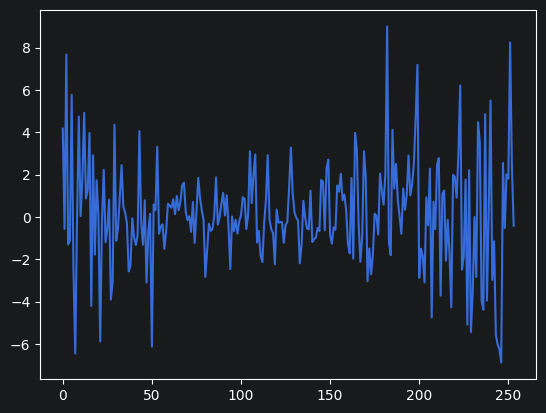

In [134]:
import matplotlib.pyplot as plt

plt.plot(trades.trade_return_pct)

## Equity curve (function unchanged from the original notebook)

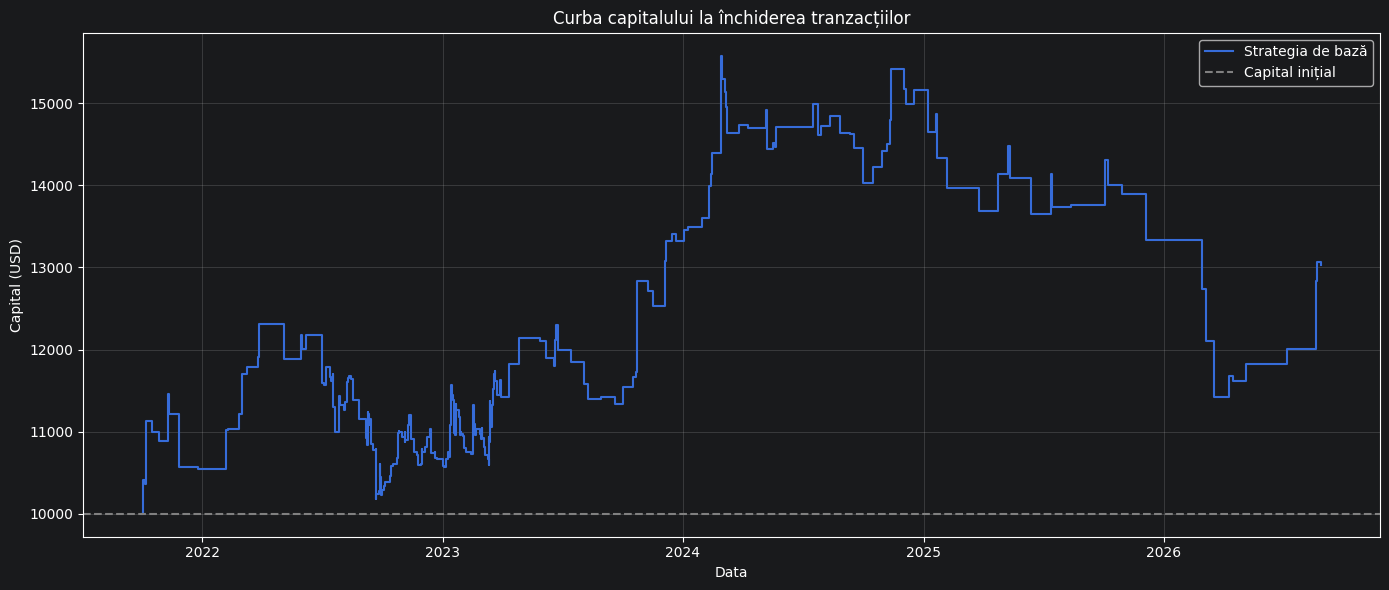

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,13026.39765,3026.39765,254,100.0,50.393701,0.11915


In [135]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_strategy_equity(
    trades,
    model=None,
    feature_cols=None,
    threshold=0.50,
    initial_capital=10_000,
    position_size=10_000,
):
    t = trades.loc[trades["trade_status"].eq("closed")].copy()

    if t.empty:
        raise ValueError("Nu există tranzacții închise.")

    t["entry_time"] = pd.to_datetime(t["entry_time"], utc=True)
    t["exit_time"] = pd.to_datetime(t["exit_time"], utc=True)
    t = t.sort_values("exit_time", kind="stable").reset_index(drop=True)

    net_return = t["trade_return"]  # Include deja costurile simulatorului.
    pnl = net_return * position_size
    dates = [t["entry_time"].min(), *t["exit_time"].tolist()]

    selections = {
        "Strategia de bază": pd.Series(True, index=t.index),
    }

    if model is not None:
        if feature_cols is None:
            feature_cols = list(model.feature_names_in_)

        positive_class = list(model.classes_).index(1)
        p_profit = model.predict_proba(t[list(feature_cols)])[:, positive_class]

        selections[f"Strategie + meta-model (prag {threshold:.0%})"] = (
            pd.Series(p_profit, index=t.index).ge(threshold)
        )

    fig, ax = plt.subplots(figsize=(14, 6))
    summary = []

    for name, accepted in selections.items():
        # Un semnal respins are PnL zero, pe aceeași axă de timp.
        selected_pnl = pnl.where(accepted, 0.0)
        equity = initial_capital + selected_pnl.cumsum()
        accepted_returns = net_return.loc[accepted]

        ax.step(
            dates,
            [initial_capital, *equity.tolist()],
            where="post",
            linewidth=1.5,
            label=name,
        )

        summary.append({
            "Variantă": name,
            "Capital final (USD)": equity.iloc[-1],
            "PnL net (USD)": selected_pnl.sum(),
            "Tranzacții": int(accepted.sum()),
            "Semnale păstrate (%)": 100 * accepted.mean(),
            "Win rate net (%)": 100 * accepted_returns.gt(0).mean(),
            "Randament mediu net (%)": 100 * accepted_returns.mean(),
        })

    ax.axhline(
        initial_capital, color="gray", linestyle="--", label="Capital inițial"
    )
    ax.set(title="Curba capitalului la închiderea tranzacțiilor",
           xlabel="Data", ylabel="Capital (USD)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

    return pd.DataFrame(summary).set_index("Variantă")

base_summary = plot_strategy_equity(trades)
base_summary

## Meta-model evaluation (as in the original notebook)

In [136]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(penalty="l2", C=1.0, max_iter=1000),
)

from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

cat_model = CatBoostClassifier(
    iterations=150,
    depth=2,
    learning_rate=0.03,
    l2_leaf_reg=10,
    loss_function="Logloss",
    random_seed=42,
    verbose=False,
)

In [137]:
from sklearn.model_selection import train_test_split

# `model_inputs` = columns known at decision time (strategy features + requested bar columns).
model_inputs = result.model_input_columns

trades = trades.sort_values("decision_time").reset_index(drop=True).copy()   # original: sort_values("signal_time")

# The original notebook derived di_diff, atr_rel and ema_distance here; the library provides them as the optional
# Donchian features (same formulas: plus_di - minus_di, atr_value / close, close / ema - 1).
features = [
    "adx_value",
    "di_diff",
    "long_breakout_atr",
    "ema_distance",
] + ML_BAR_FEATURES

assert set(features) <= set(model_inputs), "every model input must be a decision-time column"
assert not set(features) & set(result.post_decision_columns)

train_events, test_events = train_test_split(
    trades, test_size=0.30, shuffle=False
)

test_start = test_events["decision_time"].iloc[0]   # original: signal_time
train_events = train_events.loc[train_events["exit_time"] < test_start]

X_train = train_events[features]
y_train = train_events["trade_return"].gt(0).astype("int8")

X_test = test_events[features]
y_test = test_events["trade_return"].gt(0).astype("int8")

baseline.fit(X_train, y_train)
cat_model.fit(X_train, y_train)

/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


CatBoostClassifier(depth=2, iterations=150, l2_leaf_reg=10, learning_rate=0.03, loss_function='Logloss', random_seed=42, verbose=False)

In [138]:
from sklearn.metrics import classification_report

y_pred_baseline = baseline.predict(X_test)
y_pred_cat_model = cat_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_baseline,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

print(classification_report(
    y_test,
    y_pred_cat_model,
    labels=[0, 1],
    target_names=["Fără profit net", "Profit net pozitiv"],
    digits=3,
    zero_division=0,
))

                    precision    recall  f1-score   support

   Fără profit net      0.466     0.794     0.587        34
Profit net pozitiv      0.632     0.279     0.387        43

          accuracy                          0.506        77
         macro avg      0.549     0.537     0.487        77
      weighted avg      0.558     0.506     0.475        77

                    precision    recall  f1-score   support

   Fără profit net      0.560     0.824     0.667        34
Profit net pozitiv      0.778     0.488     0.600        43

          accuracy                          0.636        77
         macro avg      0.669     0.656     0.633        77
      weighted avg      0.682     0.636     0.629        77



/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [139]:
from sklearn.metrics import roc_auc_score

p_test_baseline = baseline.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_baseline):.4f}")

p_test_cat_model = cat_model.predict_proba(X_test)[:, 1]
print(f"ROC-AUC: {roc_auc_score(y_test, p_test_cat_model):.4f}")

ROC-AUC: 0.6170
ROC-AUC: 0.6477


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


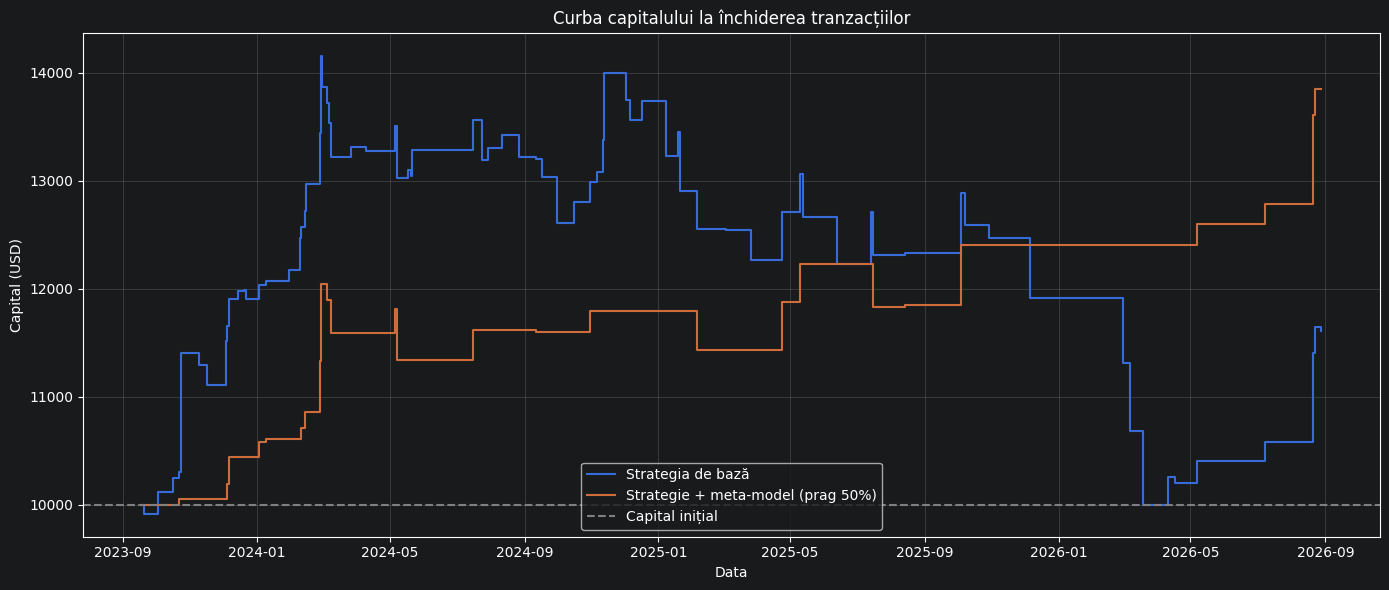

,Capital final (USD),PnL net (USD),Tranzacții,Semnale păstrate (%),Win rate net (%),Randament mediu net (%)
Variantă,,,,,,
Strategia de bază,11605.191596,1605.191596,77,100.000000,55.844156,0.208466
Strategie + meta-model (prag 50%),13846.864336,3846.864336,27,35.064935,77.777778,1.424765


In [140]:
meta_summary = plot_strategy_equity(test_events, cat_model, feature_cols=features, threshold=0.5)
meta_summary

In [141]:
from sklearn.metrics import log_loss, roc_auc_score

for name, p_test in [
    ("Baseline", p_test_baseline),
    ("CatBoost", p_test_cat_model),
]:
    auc = roc_auc_score(y_test, p_test)
    neg_loss = -log_loss(y_test, p_test, labels=[0, 1])

    print(f"{name:10s} | ROC-AUC: {auc:.4f} | Neg Log Loss: {neg_loss:.4f}")

Baseline   | ROC-AUC: 0.6170 | Neg Log Loss: -0.6967
CatBoost   | ROC-AUC: 0.6477 | Neg Log Loss: -0.6830


## Reproduction check against the original notebook

Values below are the outputs stored in `primary_strategies.ipynb` (same data, same experiment). The strategy numbers
are deterministic and must match exactly; the model metrics depend on the installed scikit-learn / CatBoost.

In [142]:
import numpy as np

# --- strategy numbers (outputs of cells "df.trade_id.count()" and the two plot_strategy_equity calls)
assert trades.trade_id.count() == 254
row = base_summary.iloc[0]
assert np.isclose(row["Capital final (USD)"], 13026.39765, atol=1e-4)
assert np.isclose(row["PnL net (USD)"], 3026.39765, atol=1e-4)
assert np.isclose(row["Win rate net (%)"], 50.393701, atol=1e-5)
assert np.isclose(row["Randament mediu net (%)"], 0.11915, atol=1e-5)

base_row, meta_row = meta_summary.iloc[0], meta_summary.iloc[1]
assert (base_row["Tranzacții"], meta_row["Tranzacții"]) == (77, 27)
assert np.isclose(base_row["Capital final (USD)"], 11605.191596, atol=1e-4)
assert np.isclose(meta_row["Capital final (USD)"], 13846.864336, atol=1e-4)
print("strategy and equity numbers: identical to the original notebook")

# --- model metrics (stored outputs: AUC 0.6170 / 0.6477, neg log loss -0.6967 / -0.6830)
p_base = baseline.predict_proba(X_test)[:, 1]
p_cat = cat_model.predict_proba(X_test)[:, 1]
checks = {
    "baseline ROC-AUC": (roc_auc_score(y_test, p_base), 0.6170),
    "catboost ROC-AUC": (roc_auc_score(y_test, p_cat), 0.6477),
    "baseline neg log loss": (-log_loss(y_test, p_base, labels=[0, 1]), -0.6967),
    "catboost neg log loss": (-log_loss(y_test, p_cat, labels=[0, 1]), -0.6830),
}
for name, (got, expected) in checks.items():
    print(f"{name:24s} got {got:+.4f} | original {expected:+.4f} | {'OK' if abs(got - expected) < 6e-5 else 'DIFFERENT'}")
assert all(abs(got - expected) < 6e-5 for got, expected in checks.values())

strategy and equity numbers: identical to the original notebook
baseline ROC-AUC         got +0.6170 | original +0.6170 | OK
catboost ROC-AUC         got +0.6477 | original +0.6477 | OK
baseline neg log loss    got -0.6967 | original -0.6967 | OK
catboost neg log loss    got -0.6830 | original -0.6830 | OK


/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['quote_spread_bps' 'quote_twa_spread_bps' 'depth_imbalance_10bps'
 'depth_imbalance_25bps' 'cost_buy_10000USDT_bps' 'book_valid_time_frac']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
